# Calcite–dolomite 1-D advection: compositions written as GEMS3K files

A variant of [calcite-dolomite-1d-advection.ipynb](calcite-dolomite-1d-advection.ipynb). The compositions of the inflowing fluid and of the column are made with the xGEMS `Material` class, equilibrated with the xGEMS `ChemicalEngine` and written as GEMS3K files, which xGEM2MT then reads with `initNodes()`. (The variant [calcite-dolomite-1d-advection-nodes.ipynb](calcite-dolomite-1d-advection-nodes.ipynb) sets the compositions directly, without files.)

### How xGEM2MT reads the GEMS3K files

| File | Contents |
|---|---|
| `*-dch.dat` | the chemical system: elements, species, phases, thermodynamic data; the same for all nodes |
| `*-ipm.dat` | settings of the GEM solver |
| `*-dbr-0-0000.dat`, `*-dbr-0-0001.dat`, ... | one composition each (bulk composition, T, P and the equilibrium speciation) |
| `*-dat.lst` | `-t` (text files), then the dch, ipm and dbr file names; the dbr names are separated by commas |
| `*-dbr.lst` | (optional) the dbr file names again; GEMS writes it, and `initNodes(dat_lst, dbr_lst)` reads the initial systems from it |

* `initNodes("...-dat.lst")` reads the initial systems from the dbr names in the `*-dat.lst` file.
* The **position** of a dbr file in the list is the index of the initial system: the first file is system 0, the second is system 1. The numbers in the file names (`-dbr-<time point>-<index>`) only follow the GEMS export convention; xGEM2MT does not read them.
* Each node is set up from one initial system. In mode 'A', nodes 0 and 1 get system 0 (inflowing fluid) and all other nodes system 1 (column). `setDistributing(node, system)` changes this; `nodesOfSystem(system)` lists the nodes of a system.

Here: system 0 = `MaterialColumn-dbr-0-0000.dat` (MgCl$_2$ solution), system 1 = `MaterialColumn-dbr-0-0001.dat` (calcite column).

## Make the compositions and write the files

### Node size

xGEM2MT has one length: the column length (`setSpatialDimensions`). The node length is the column length / number of nodes. There is no cross-section area and no node volume.

A node contains the amounts that you give it: here 1 kg of pore water, the minerals for that water, and an inert solid. Only the amounts **per kg of water** matter: if you multiply all amounts of all nodes by 10, the results per kg of water do not change. To convert a rock description: mineral amount per kg of water = mol of mineral per litre of bulk rock / (porosity × 1 kg/L).

Give **all nodes the same mass of water**. With different masses in neighbouring nodes, mode 'A' does not conserve water and dissolved amounts. To make a zone different, change its mineral amount per kg of water and its porosity.

**The inert solid.** The chemical system has an element `Inert` (a solid phase `Inert` that does not react; in the original xGEMS benchmark files it is tin, Sn). It stands for the solid matrix of the rock. Each node gets 100 mol of it. Its molar volume in the file (0.0213 L/mol) is chosen so that 100 mol (2.13 L) and 1 kg of water (1.00 L) give a node of 3.13 L with porosity 0.32.
* Mode 'A' does not need it for the transport: it moves only the dissolved amounts, and the porosity is a transport value. Without it the results are the same.
* With it, GEM needs 3 to 5 times fewer iterations (the number of moles counts: the more moles, the fewer iterations), so the run is faster. But the trace amounts of a cold start (AIA) can differ by about 0.2 % (test cases: `gems-benchmark/Resources/under_review/xgems_CalciteColumn_Sn` and `_noSn`).
* `Material` knows only the chemical elements in formulas, so the inert solid is added as an element amount: `add({"Inert": n}, 1.0, "mol")`.

**Two porosities.** The transport porosity and the porosity of the chemical system are two different values:
* The **transport porosity** is a number that you give (`setInitialNodeEffectivePorosity`, or `porosity` in `TransportProperties`). Mode 'A' uses it only in the diffusion part of the dispersion coefficient. Here the diffusivity is 0, so it has no effect.
* The **porosity of the chemical system** is not a parameter: it is the water volume / node volume, from the amounts in the node. GEMS and xGEM2MT do not use it. It changes a little when minerals dissolve or precipitate; the transport porosity stays the same (mode 'A' has no porosity feedback).

Give both the same value, so that the node is described consistently. Here both are 0.32.

Each material also gets a little O$_2$, so that the redox state is defined. Elements that are not in a material get a trace amount (`min_amount`, default 1e-11 mol).

In [1]:
import os, shutil
from xgems import ChemicalEngine, Material

# The xGEMS engine gives Material the element list and the molar masses
gems = ChemicalEngine("CalciteColumn/CalciteColumn-dat.lst")

water = 1.0        # kg of pore water in every node (the same mass in all nodes)
n_inert = 100.0    # mol of inert solid: 2.13 L with its molar volume in the file (0.0213 L/mol),
                   # so a node with 1 kg of water (1.00 L) has 3.13 L and a chemical porosity of 0.32

# All amounts are given per kg of water, times the mass of water of the node
fluid = Material(gems, "MgCl2 solution")       # inflowing fluid, system 0
fluid.add("H2O", water, "kg")
fluid.add("MgCl2", 1e-3 * water, "mol")        # 1 mmol per kg of water
fluid.add("O2", 1e-5 * water, "mol")           # a little O2: defines the redox state
fluid.add({"Inert": n_inert}, 1.0, "mol")      # inert solid matrix

column = Material(gems, "calcite column")      # column, system 1
column.add("H2O", water, "kg")
column.add("CaCO3", 3.405e-4 * water, "mol")   # calcite and its dissolved part, per kg of water
column.add("O2", 1e-4 * water, "mol")
column.add({"Inert": n_inert}, 1.0, "mol")     # inert solid matrix

# New folder with the unchanged dch and ipm files
os.makedirs("MaterialColumn", exist_ok=True)
shutil.copy("CalciteColumn/CalciteColumn-dch.dat", "MaterialColumn")
shutil.copy("CalciteColumn/CalciteColumn-ipm.dat", "MaterialColumn")

# Equilibrate each composition and write it as a dbr file
for m, dbr in [(fluid, "MaterialColumn-dbr-0-0000.dat"), (column, "MaterialColumn-dbr-0-0001.dat")]:
    gems.setColdStart()
    gems.equilibrate(298.15, 1e5, m.b())
    gems.writeDbrToFile("MaterialColumn/" + dbr)
    print(f"{dbr}: {m.name}, pH {gems.pH():.2f}")

# The file list; the order of the dbr files gives the system index (0, 1)
with open("MaterialColumn/MaterialColumn-dat.lst", "w") as f:
    f.write('-t "CalciteColumn-dch.dat" "CalciteColumn-ipm.dat" '
            '"MaterialColumn-dbr-0-0000.dat", "MaterialColumn-dbr-0-0001.dat"\n')

MaterialColumn-dbr-0-0000.dat: MgCl2 solution, pH 6.95
MaterialColumn-dbr-0-0001.dat: calcite column, pH 9.91


## Set up and run the transport

The same as in the original notebook; only the file in `initNodes` changes.

All functions and their parameters: [MassTransport in Python](https://github.com/gemshub/xgem2mt/blob/master/docs/python-mass-transport.md).

### Names of the transport values

Some names look alike but are different values. This notebook uses only the names in the first column:

| Name | Symbol | Unit | Meaning | All nodes (before `initNodes`) | Some nodes (`TransportProperties`) |
|---|---|---|---|---|---|
| velocity | v | m/s | pore velocity of the water | `setFluidAdvectionVelocity` | `velocity` (changes only the dispersion) |
| porosity | φ | – | pore volume / bulk volume | `setInitialNodeEffectivePorosity` | `porosity` |
| **dispersivity** | α | m | a length of the porous medium: how much the flow spreads the solutes | `setInitialDispersivity` | `dispersivity` |
| **diffusivity** | D<sub>w</sub> | m²/s | diffusion coefficient of the solutes in water | `setInitialDiffusivity` | `diffusivity` |
| tortuosity | τ | – | how much longer the diffusion path is than the column | `setInitialTortuosityFactor` | `tortuosity` |
| **dispersion coefficient** | D | m²/s | the program calculates it: D = α·v + D<sub>w</sub>·φ/τ | – | – |
| node length | Δx | m | column length / number of nodes | `setSpatialDimensions`, `MassTransport(mode, n)` | – |
| time step | Δt | s | the program calculates it (see the comment at `setTau`) | – | – |

Here the diffusivity is 0, so D = α·v = 0.0067 m × 9.375·10⁻⁶ m/s = 6.3·10⁻⁸ m²/s. Porosity, diffusivity and tortuosity change only the diffusion part of D.

Not used in mode 'A', thus not set here: `setInitialTotalNodeVolume`, `setInitialEffectivePermeability`, `setTypeFluxPhase`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from xgem2mt import MassTransport

In [3]:
results = {}

def monitor(engine, step, time):
    nodes = range(engine.nNodes())
    aq = [engine.elementAmountsInPhase(n, "aq_gen") / engine.phaseMass(n, "aq_gen") for n in nodes]
    results[time] = {
        "Ca": [c[engine.indexElement("Ca")] for c in aq],
        "Mg": [c[engine.indexElement("Mg")] for c in aq],
        "Cl": [c[engine.indexElement("Cl")] for c in aq],
        "Calcite":  [engine.phaseAmount(n, "Calcite") for n in nodes],
        "Dolomite": [engine.phaseAmount(n, "Dolomite-dis") for n in nodes],
    }

In [4]:
nnodes = 80

# (1) Create the MassTransport simulator in 'A' mode (1-D advection, finite differences)
mt_task = MassTransport("A", nnodes)
mt_task.setName("Calcite-dolomite 1-D advection benchmark")

# (2) Time: start, end, step, in s. The program calculates the time step itself, as the smaller of
#       0.5 * node length / velocity                       advection limit:  333 s here
#       node length**2 / (4 * dispersion coefficient)      dispersion limit: 155 s here
#     (node length 0.00625 m, dispersion coefficient 6.3e-8 m2/s: see the table of names above).
#     The run stops at the first step at or after 'end' (here 21144 s), or after (end - start)/step + 1
#     steps. Keep 'step' smaller than the time step, or the run stops too early.
mt_task.setTau(0.0, 21000.0, 10.0)
mt_task.setSpatialDimensions(0.5)            # column length, m; node length = column length / nnodes (y, z: not used)
mt_task.setSIA("+")  # GEM start in each node: "+" from the previous step (SIA, ~5x faster), "-" from scratch (AIA)
mt_task.setOutput(False)

# Transport values for all nodes (names: see the table above)
mt_task.setTimeStepReductionFactor(1.0)          # the time step is divided by this factor; 1 = not reduced
mt_task.setFluidAdvectionVelocity(9.375e-6)      # velocity, m/s (pore velocity)
mt_task.setInitialNodeEffectivePorosity(0.32)    # porosity
mt_task.setInitialDispersivity(0.0067)           # dispersivity, m
mt_task.setInitialDiffusivity(0.0)               # diffusivity, m2/s (0: no diffusion)
mt_task.setInitialTortuosityFactor(1.0)          # tortuosity
mt_task.setMonitoring(monitor)

# (3) Read the files written above: nodes 0 and 1 get the inflowing fluid (system 0), the others the column (system 1)
mt_task.initNodes("MaterialColumn/MaterialColumn-dat.lst")

`print(mt_task)` (or `mt_task.summary()`) shows the setup: the column, the time step that the program uses, which nodes are fluid and column, their properties and phases, and which function changes each value.

In [5]:
print(mt_task)

MassTransport "Calcite-dolomite 1-D advection benchmark"
Mode A: 1-D advection + dispersion, explicit finite differences
Column           0.5 m, 80 nodes, node length 0.00625 m
                 [setSpatialDimensions(x), MassTransport(mode, nnodes)]
Velocity         9.375e-06 m/s (pore velocity, all nodes)  [setFluidAdvectionVelocity(velocity)]
Time             0 .. 21000, step 10  [setTau(start, stop, step)]
Time step        155.5 s (dispersion; advection limit 333.3 s, dispersion limit 155.5 s),
                 reduction factor 1
                 [set by the program; divided by setTimeStepReductionFactor(factor)]
Steps            about 136, to t = 21144.279  [stop time and setTau step]
Initial systems  0 = MaterialColumn-dbr-0-0000.dat,  1 = MaterialColumn-dbr-0-0001.dat
                 [initNodes(dat_lst) reads the dbr files in their order]

  flow ->
  nodes   | 0-1            | 2-78    | 79             |
  role    | inflow, fixed  | column  | outlet, fixed  |
  system  | 0       

In [6]:
import time

start = time.perf_counter()
mt_task.runMassTransport()
elapsed = time.perf_counter() - start

times = sorted(results)
x = (np.arange(nnodes) + 0.5) * 0.5 / nnodes   # node centres, m
end = results[times[-1]]
print(f"Simulated: {len(times)} time steps up to t = {times[-1]:.0f} s of model time")
print(f"Computing time: {elapsed:.1f} s")

Simulated: 136 time steps up to t = 21144 s of model time
Computing time: 2.9 s


## Plot the results

Dissolved Ca, Mg and Cl along the column at the final time:

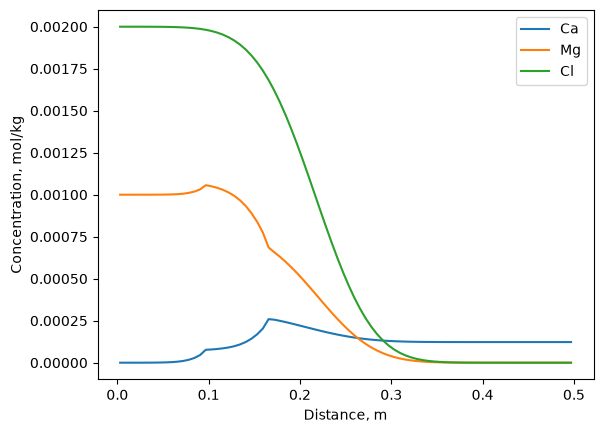

In [7]:
for name in ("Ca", "Mg", "Cl"):
    plt.plot(x, end[name], label=name)
plt.xlabel("Distance, m"); plt.ylabel("Concentration, mol/kg"); plt.legend(); plt.show()

Calcite and dolomite at the final time:

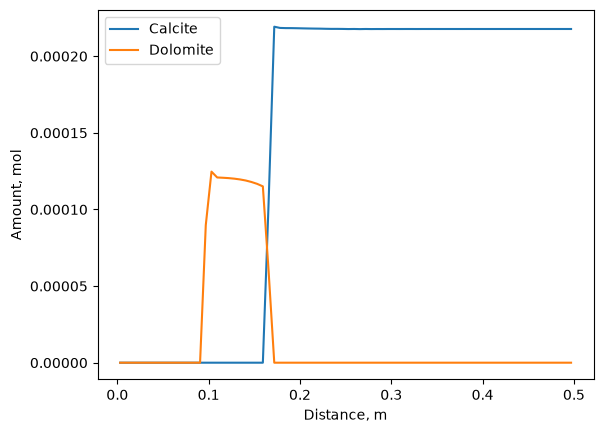

In [8]:
plt.plot(x, end["Calcite"], label="Calcite")
plt.plot(x, end["Dolomite"], label="Dolomite")
plt.xlabel("Distance, m"); plt.ylabel("Amount, mol"); plt.legend(); plt.show()

The dolomite zone moves along the column with time:

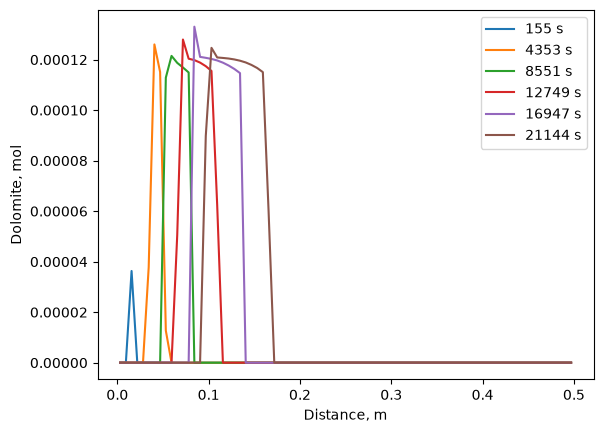

In [9]:
for t in times[::27]:
    plt.plot(x, results[t]["Dolomite"], label=f"{t:.0f} s")
plt.xlabel("Distance, m"); plt.ylabel("Dolomite, mol"); plt.legend(); plt.show()

**Breakthrough curves**: the dissolved amounts against time at fixed points of the column, as in the effluent of a column experiment. The x axis is the number of pore volumes, velocity × time / column length.

This run lasts 0.39 pore volumes, so the reaction front (at about 0.17 m) does not get to the outlet. The plot therefore shows three points inside the column and the outlet. The outlet is node n − 2: the last node keeps its start composition. To compare with the effluent of an experiment, run for at least 1 to 2 pore volumes, e.g. `setTau(0.0, 2 * 0.5 / 9.375e-6, 10.0)` (107 000 s).

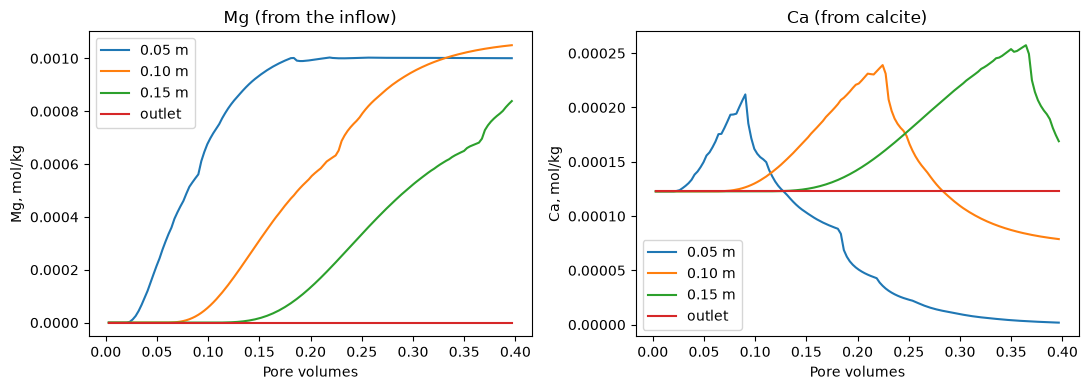

In [10]:
velocity, length = 9.375e-6, 0.5                  # as in the setup above
pore_volumes = np.array(times) * velocity / length
points = {"0.05 m": 8, "0.10 m": 16, "0.15 m": 24, "outlet": nnodes - 2}   # node = position / node length

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, node in points.items():
    axes[0].plot(pore_volumes, [results[t]["Mg"][node] for t in times], label=label)
    axes[1].plot(pore_volumes, [results[t]["Ca"][node] for t in times], label=label)
axes[0].set(xlabel="Pore volumes", ylabel="Mg, mol/kg", title="Mg (from the inflow)")
axes[1].set(xlabel="Pore volumes", ylabel="Ca, mol/kg", title="Ca (from calcite)")
axes[0].legend(); axes[1].legend(); plt.tight_layout(); plt.show()